### Import Library dan Load Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set gaya tampilan plot
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Load dataset
df = pd.read_csv('Klasifikasi Tingkat Kemiskinan di Indonesia.csv')

print(f"Dataset berhasil dimuat dengan ukuran: {df.shape[0]} baris dan {df.shape[1]} kolom.\n")

Dataset berhasil dimuat dengan ukuran: 514 baris dan 13 kolom.



### Data Dictionary (Variabel, Tipe, Unit)

In [2]:
# Pemetaan unit/satuan secara eksplisit
units = {
    'Provinsi': 'Nama Kategori',
    'Kab/Kota': 'Nama Kategori',
    'Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)': 'Persen (%)',
    'Rata-rata Lama Sekolah Penduduk 15+ (Tahun)': 'Tahun',
    'Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)': 'Ribu Rp/Orang/Th',
    'Indeks Pembangunan Manusia': 'Indeks (0-100)',
    'Umur Harapan Hidup (Tahun)': 'Tahun',
    'Persentase rumah tangga yang memiliki akses terhadap sanitasi layak': 'Persen (%)',
    'Persentase rumah tangga yang memiliki akses terhadap air minum layak': 'Persen (%)',
    'Tingkat Pengangguran Terbuka': 'Persen (%)',
    'Tingkat Partisipasi Angkatan Kerja': 'Persen (%)',
    'PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah)': 'Rupiah',
    'Klasifikasi Kemiskinan': 'Binary (0 / 1)'
}

data_dict = []
for col in df.columns:
    is_numeric = np.issubdtype(df[col].dtype, np.number)
    data_dict.append({
        'Nama Variabel': col,
        'Tipe Data': str(df[col].dtype),
        'Satuan/Unit': units.get(col, '-'),
        'Nilai Min': df[col].min() if is_numeric else '-',
        'Nilai Max': df[col].max() if is_numeric else '-'
    })

df_data_dictionary = pd.DataFrame(data_dict)

print("="*60)
print("1. DATA DICTIONARY")
print("="*60)
print(df_data_dictionary.to_string(index=False))

1. DATA DICTIONARY
                                                       Nama Variabel Tipe Data      Satuan/Unit Nilai Min Nilai Max
                                                            Provinsi    object    Nama Kategori         -         -
                                                            Kab/Kota    object    Nama Kategori         -         -
     Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)   float64       Persen (%)      2.38     41.66
                         Rata-rata Lama Sekolah Penduduk 15+ (Tahun)   float64            Tahun      1.42     12.83
        Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)     int64 Ribu Rp/Orang/Th      3976     23888
                                          Indeks Pembangunan Manusia   float64   Indeks (0-100)     32.84     87.18
                                          Umur Harapan Hidup (Tahun)   float64            Tahun     55.43     77.73
 Persentase rumah tangga yang memiliki akses terhadap

### Kualitas Data (Missing Value, Duplikasi, Outlier)

In [3]:
print("\n" + "="*60)
print("2. CEK KUALITAS DATA")
print("="*60)

# A. Cek Missing Values
missing_val = df.isnull().sum()
print("\n[A] Jumlah Missing Value per Kolom:")
print(missing_val)

# B. Cek Duplikasi Baris
duplicate_count = df.duplicated().sum()
print(f"\n[B] Total Baris Duplikat: {duplicate_count}")

# C. Deteksi Outlier Menggunakan Metode IQR (1.5 * IQR)
numeric_cols = df.select_dtypes(include=[np.number]).columns

print("\n[C] Jumlah Outlier per Fitur Numerik (Metode IQR):")
outlier_results = []
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_results.append({
        'Fitur': col,
        'Jumlah Outlier': len(outliers),
        'Persentase Outlier': f"{(len(outliers) / len(df)) * 100:.2f}%"
    })

df_outliers = pd.DataFrame(outlier_results)
print(df_outliers.to_string(index=False))


2. CEK KUALITAS DATA

[A] Jumlah Missing Value per Kolom:
Provinsi                                                                0
Kab/Kota                                                                0
Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)         0
Rata-rata Lama Sekolah Penduduk 15+ (Tahun)                             0
Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)            0
Indeks Pembangunan Manusia                                              0
Umur Harapan Hidup (Tahun)                                              0
Persentase rumah tangga yang memiliki akses terhadap sanitasi layak     0
Persentase rumah tangga yang memiliki akses terhadap air minum layak    0
Tingkat Pengangguran Terbuka                                            0
Tingkat Partisipasi Angkatan Kerja                                      0
PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah)              0
Klasifikasi Kemiskinan                               

### EDA Berinsight (Distribusi Target & Korelasi)


3. EXPLORATORY DATA ANALYSIS (EDA) BERINSIGHT

[A] Distribusi Kelas Target (Klasifikasi Kemiskinan):
- Kelas 0: 452 kabupaten/kota (87.94%)
- Kelas 1: 62 kabupaten/kota (12.06%)


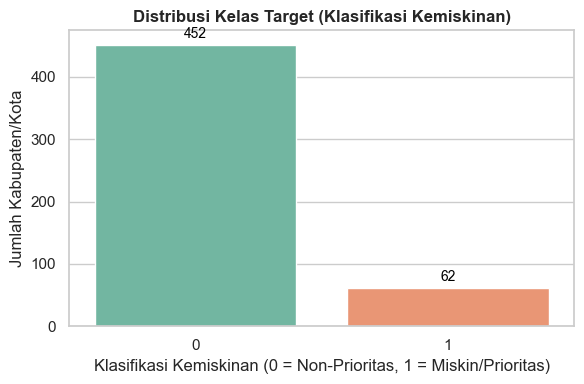


[B] Korelasi Fitur Terhadap 'Klasifikasi Kemiskinan':
Klasifikasi Kemiskinan                                                  1.000000
Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)         0.756329
Tingkat Partisipasi Angkatan Kerja                                      0.349023
PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah)             -0.141300
Tingkat Pengangguran Terbuka                                           -0.237316
Persentase rumah tangga yang memiliki akses terhadap air minum layak   -0.306757
Rata-rata Lama Sekolah Penduduk 15+ (Tahun)                            -0.366719
Persentase rumah tangga yang memiliki akses terhadap sanitasi layak    -0.444003
Umur Harapan Hidup (Tahun)                                             -0.449205
Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)           -0.456122
Indeks Pembangunan Manusia                                             -0.535125
Name: Klasifikasi Kemiskinan, dtype: float64


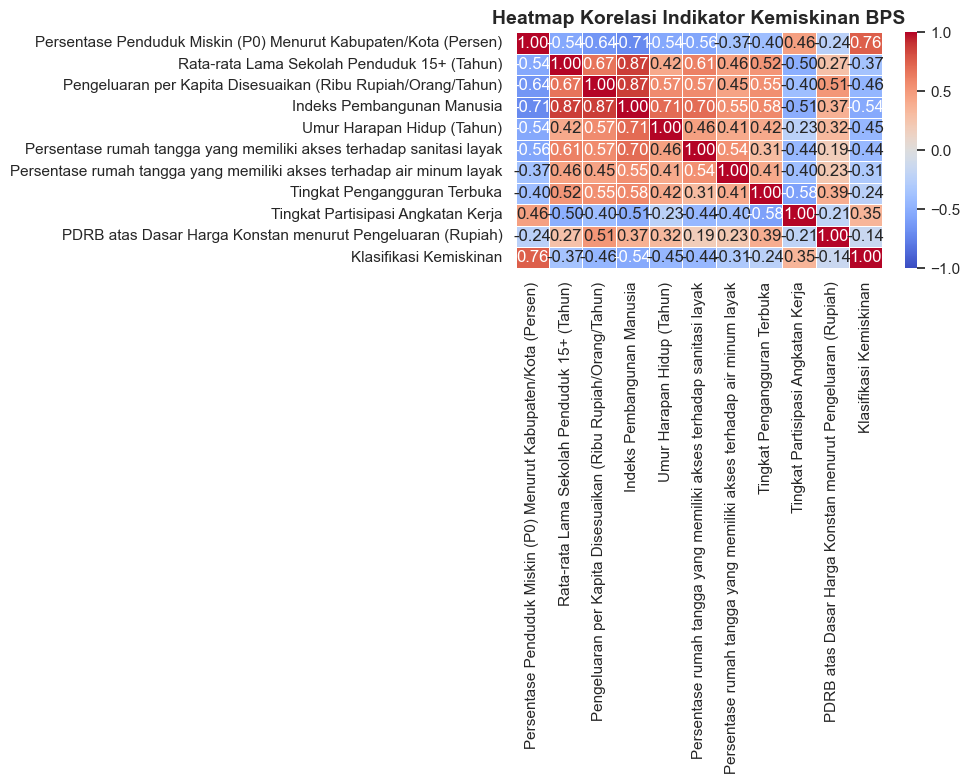

In [5]:
print("\n" + "="*60)
print("3. EXPLORATORY DATA ANALYSIS (EDA) BERINSIGHT")
print("="*60)

# A. Distribusi Kelas Target
target_counts = df['Klasifikasi Kemiskinan'].value_counts()
target_props = df['Klasifikasi Kemiskinan'].value_counts(normalize=True) * 100

print("\n[A] Distribusi Kelas Target (Klasifikasi Kemiskinan):")
for cls in target_counts.index:
    print(f"- Kelas {cls}: {target_counts[cls]} kabupaten/kota ({target_props[cls]:.2f}%)")

# Visualisasi Distribusi Target
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='Klasifikasi Kemiskinan', hue='Klasifikasi Kemiskinan', palette='Set2', legend=False)
plt.title('Distribusi Kelas Target (Klasifikasi Kemiskinan)', fontsize=12, fontweight='bold')
plt.xlabel('Klasifikasi Kemiskinan (0 = Non-Prioritas, 1 = Miskin/Prioritas)')
plt.ylabel('Jumlah Kabupaten/Kota')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')
plt.tight_layout()
plt.show()

# B. Korelasi Antar Fitur Numerik terhadap Target
print("\n[B] Korelasi Fitur Terhadap 'Klasifikasi Kemiskinan':")
corr_matrix = df[numeric_cols].corr()
target_corr = corr_matrix['Klasifikasi Kemiskinan'].sort_values(ascending=False)
print(target_corr)

# Visualisasi Heatmap Korelasi
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Heatmap Korelasi Indikator Kemiskinan BPS', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()